In [18]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [20]:
df = pd.read_csv('gold_data.csv')
df_clean = df.dropna()

df_clean.to_csv("gold_data_clean.csv", index=False)

print("Số dòng ban đầu:", len(df))
print("Số dòng sau khi làm sạch:", len(df_clean))

df_clean.head()

Số dòng ban đầu: 43
Số dòng sau khi làm sạch: 40


,Quarter,Gold_Price_USD_oz,Gold_Demand_tonnes,Jewellery_Demand_tonnes,Bar_and_Coin_Demand_tonnes,DFII10,CPIAUCSL
2,2016Q3,1334.776154,1038.132578,508.859303,201.416121,0.115714,241.176000
3,2016Q4,1221.553279,957.737453,642.510218,381.043973,0.328361,242.134667
4,2017Q1,1219.488281,1139.405796,532.074283,305.460386,0.438548,243.838667
5,2017Q2,1256.590984,1044.294030,536.771528,251.100551,0.440952,244.120000
6,2017Q3,1277.908594,990.647757,516.317169,234.307769,0.448413,245.287000


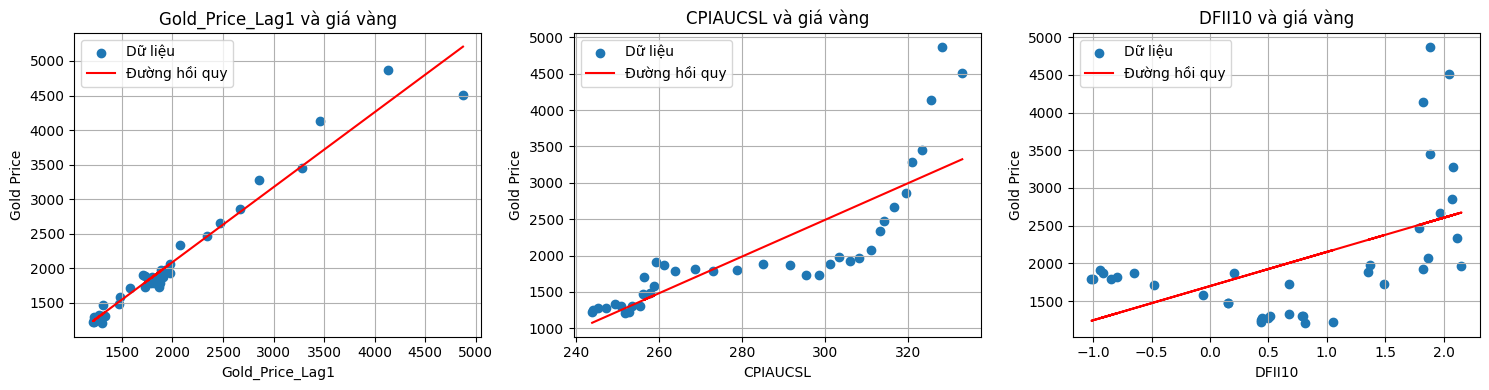

In [26]:
# Tạo biến giá vàng quý trước
df_clean["Gold_Price_Lag1"] = df_clean["Gold_Price_USD_oz"].shift(1)
df_clean = df_clean.dropna().reset_index(drop=True)

# Chọn giá vàng
y = df_clean["Gold_Price_USD_oz"]

# Danh sách 3 biến cần so sánh
variables = ["Gold_Price_Lag1", "CPIAUCSL", "DFII10"]

# Vẽ biểu đồ
plt.figure(figsize=(15, 4))

for i, col in enumerate(variables):
    x = df_clean[col]

    # Tính đường hồi quy
    a, b = np.polyfit(x, y, 1)

    plt.subplot(1, 3, i + 1)
    plt.scatter(x, y, label="Dữ liệu")
    plt.plot(x, a*x + b, color="red", label="Đường hồi quy")

    plt.xlabel(col)
    plt.ylabel("Gold Price")
    plt.title(col + " và giá vàng")
    plt.legend()
    plt.grid()

plt.tight_layout()
plt.show()

R2 Train: 0.9245
R2 Test: 0.6125
RMSE Train: 85.47
RMSE Test: 516.41


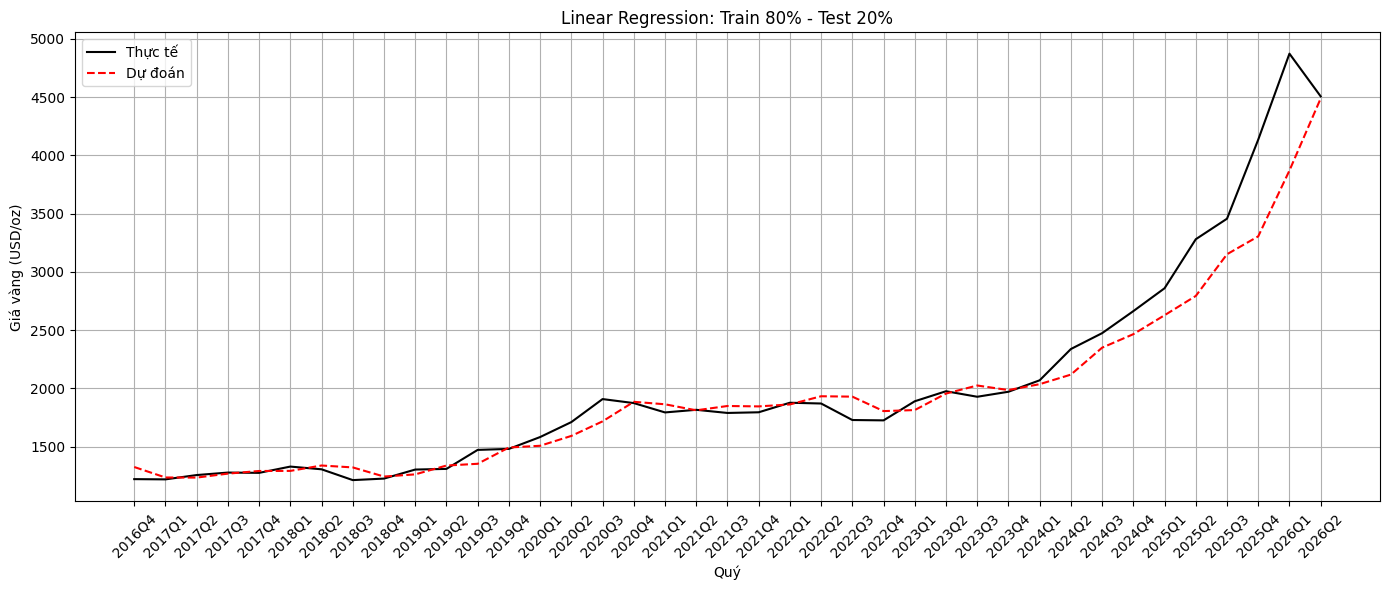

In [25]:
# Chọn biến
df["Gold_Price_Lag1"] = df["Gold_Price_USD_oz"].shift(1)

# Loại bỏ dữ liệu thiếu
df = df.dropna(subset=[
    "Gold_Price_Lag1",
    "Gold_Price_USD_oz",
    "CPIAUCSL",
    "DFII10"
]).copy().reset_index(drop=True)

X = df[["Gold_Price_Lag1", "CPIAUCSL", "DFII10"]]
y = df["Gold_Price_USD_oz"]

# Chia Train/Test
split = int(len(df) * 0.8)

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

# Huấn luyện
model = LinearRegression()
model.fit(X_train, y_train)

# Dự đoán
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

# Đánh giá
print("R2 Train:", round(r2_score(y_train, train_pred), 4))
print("R2 Test:", round(r2_score(y_test, test_pred), 4))

print("RMSE Train:", round(np.sqrt(mean_squared_error(y_train, train_pred)), 2))
print("RMSE Test:", round(np.sqrt(mean_squared_error(y_test, test_pred)), 2))

# Vẽ biểu đồ
plt.figure(figsize=(14, 6))

predictions = np.concatenate([train_pred, test_pred])

plt.plot(df["Quarter"], y, color="black", label="Thực tế")
plt.plot(df["Quarter"], predictions, "r--", label="Dự đoán")

plt.xticks(rotation=45)
plt.title("Linear Regression: Train 80% - Test 20%")
plt.xlabel("Quý")
plt.ylabel("Giá vàng (USD/oz)")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()